In [ ]:
!pip install medmnist

import os
import random
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision.transforms as transforms

import pandas as pd

import medmnist
from medmnist import INFO, Evaluator

from sklearn.metrics import (
    classification_report,
    confusion_matrix
    f1_score,
    recall_score
)

import seaborn as sns




# Fissiamo i seed per aumentare la riproducibilità degli esperimenti.
SEED = 42

def set_seed(seed=42):
  random.seed(seed)

  np.random.seed(seed)

  torch.manual_seed(seed)

  # Se è disponibile una GPU, fissa anche i seed CUDA
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)# imposta il seed per le operazioni casuali eseguite sulla GPU.
      torch.cuda.manual_seed_all(seed) #imposta il seed per le operazioni casuali eseguite sulla GPU.

  # Forza, quando possibile, operazioni deterministiche con cuDNN.
  torch.backends.cudnn.deterministic = True

  # Disattiva la ricerca automatica dell'algoritmo più veloce,
  # che potrebbe introdurre differenze tra diverse esecuzioni e ridurre la riproducibilità
  torch.backends.cudnn.benchmark = False
set_seed(SEED)
  # tutto ciò serve per aumentare la riproducibilità, non ad ottnere risultati sempre uguali, Hardware, versioni di PyTorch/CUDA e alcune operazioni possono comunque influire sulla riproducibilità

In [ ]:
data_flag = 'breastmnist' #etichetta per la selezione delle immagini corrette, identifica il dataset che vogliamo utilizzare, visto che MedMNIST contiene diversi dataset. Nel nostro progetto vogliamo selezionare BreastMNIST
download = True

info = INFO[data_flag] # INFO contiene le informazioni descrittive dei dataset disponibili in MedMNIST.
task = info['task'] # "binary-class"
n_channels = info['n_channels'] # 1 canale (immagini in scala di grigi)
n_classes = len(info['label']) # 2 (benigno/normale vs maligno)

DataClass = getattr(medmnist, info['python_class']) #salva la classe per breastmnist

In [ ]:
# 1. Definizione delle Trasformazioni
#training CON data augmentation
train_transform = transforms.Compose([
    # creiamo varianti artificiali delle foto
    transforms.RandomHorizontalFlip(p=0.5), # C'è il 50% di probabilità (p=0.5) che l'immagine venga ribaltata
    transforms.RandomRotation(degrees=15), # Significa che viene scelta casualmente una rotazione nell'intervallo: -15° ≤ rotazione ≤ +15°
    transforms.ToTensor(), # converte la foto da un formato immagine standard a un Tensore di PyTorch, i valori diventano compresi tra 0 e 1
    transforms.Normalize(mean=[0.5], std=[0.5]) # Applica un riscalamento fisso: x_norm=(x-0.5)/0.5, portando valori circa da [0,1] a [-1,1].
])

# Non include rotazioni o ribaltamenti perché durante il test e la validazione vogliamo misurare le prestazioni su immagini reali,
# pulite e senza distorsioni artificiali. Validation e test non ricevono augmentation casuale; vengono applicati solo ToTensor e Normalize.
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Trasformazione della CNN baseline:
# training SENZA data augmentation
baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# 2. Caricamento dei 3 Split nativi

# Training set del modello con augmentation
train_dataset = DataClass(split='train', transform=train_transform, download=download)#Ad ogni epoca applica la Data Augmentation: transform=train_transform
# Training set della baseline senza data augmentation
baseline_train_dataset = DataClass(split='train',transform=baseline_transform,download=download) # split='train' Quindi train_dataset e baseline_train_dataset utilizzano lo stesso split di training
val_dataset = DataClass(split='val', transform=eval_transform, download=download) #quindi vengono caricate le immagini del validation set.
test_dataset = DataClass(split='test', transform=eval_transform, download=download)#quindi vengono caricate le immagini del test set.

# 3. Creazione dei Dataloader: come le immagini vengono fornite alla CNN
BATCH_SIZE = 32 # Le immagini vengono organizzate in gruppi, chiamati batch, da 32 immagini.

# FUNZIONE PER CREARE UN TRAIN DATALOADER RIPRODUCIBILE
# Rende il confronto più controllato e riproducibile, utilizzando lo stesso seed per lo shuffle
# tra il modello principale (con Data Augmentation) e la Baseline (senza Data Augmentation).

def make_train_loader(dataset, seed=SEED):

    generator = torch.Generator()# crea un generatore di numeri pseudocasuali di PyTorch.

    # Imposta il seed del generatore utilizzato per lo shuffle
    generator.manual_seed(seed)


    return DataLoader(
        dataset=dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

# Training CON Data Augmentation
train_loader = make_train_loader(
    train_dataset,#Specifica quale dataset caricare
    #Divide i dati in gruppi di 32 immagini
    #Mescola l'ordine delle immagini all'inizio di ogni epoca.
    SEED

)


# Training SENZA Data Augmentation
baseline_train_loader = make_train_loader(
    baseline_train_dataset,
    SEED
)
# Rende il confronto più controllato e riproducibile, utilizzando lo stesso seed per lo shuffle.
# tra il modello principale (con Data Augmentation) e la Baseline (senza Data Augmentation).

val_loader = DataLoader(
    dataset=val_dataset,# vengono utilizzate le immagini di validation.
    batch_size=BATCH_SIZE,# vengono organizzate in batch da 32
    shuffle=False# durante la validation non stiamo addestrando il modello.
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE, #validazione del modello.
    shuffle=False
)

# 4. CALCOLO PESI

# Definizione del dispositivo (GPU o CPU), controlla se sul computer è presente una GPU.
# Se c'è, sposta i calcoli sulla GPU per velocizzare l'addestramento; altrimenti usa la normale CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Estrazione e appiattimento delle etichette del Training Set 0 Maligno 1 benigno
labels = train_dataset.labels.squeeze() # squeez da 2d Rende l'array 1D
total_samples = len(labels)

# Conteggio dei campioni per classe
c_0_count = int(np.sum(labels == 0)) # 147 campioni (Maligni)
c_1_count = int(np.sum(labels == 1)) # 399 campioni (Benigni/normali)

# Stampa del Report sullo Sbilanciamento
print("--- Analisi dello Sbilanciamento delle Classi (Train) ---")
print(f"Campioni Maligni (Classe 0): {c_0_count} ({c_0_count / total_samples * 100:.2f}%)")
print(f"Campioni Benigni/normali (Classe 1): {c_1_count} ({c_1_count / total_samples * 100:.2f}%)")

# Calcolo dei pesi bilanciati
class_weights = [total_samples / (2.0 * c_0_count), total_samples / (2.0 * c_1_count)]
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
#Senza questi pesi, la rete neurale vedrebbe molte più immagini benigni che maligni e tenderebbe
# ad imparare a riconoscere bene solo la classe maggioritaria, ignorando o sbagliando spesso i casi maligni.
#I pesi sono sostanzialmente inversamente proporzionali alla frequenza della classe.

print(f"\nPesi applicati alla Loss: Classe 0 (Maligno) = {class_weights[0]:.3f} | Classe 1 (Benigno/normale) = {class_weights[1]:.3f}")

--- Analisi dello Sbilanciamento delle Classi (Train) ---
Campioni Maligni (Classe 0): 147 (26.92%)
Campioni Benigni/normali (Classe 1): 399 (73.08%)

Pesi applicati alla Loss: Classe 0 (Maligno) = 1.857 | Classe 1 (Benigno/normale) = 0.684


In [ ]:


# DEFINIZIONE DELLA CNN
class BreastCNN(nn.Module):
    def __init__(
        self,
        in_channels,#numero di canali, 1 in caso di immagini in scala di grigi
        num_classes,#Il numero di risposte finali che la rete deve dare: maligno - benigno.
        channels_1=16,#Il numero di filtri nel primo blocco convoluzionale. -> produce 16 feature map
        channels_2=32,#Il numero di filtri nel secondo blocco convoluzionale -> produce 32 feature map
        latent_dim=64#Il numero di neuroni nello strato denso nascosto
    ):

        super(BreastCNN, self).__init__() #inizializza la classe base nn.Module

       # Blocco Convoluzionale
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels, channels_1,kernel_size=3, padding=1), # Produce channels_1 feature map; nella configurazione Base channels_1=16
            nn.BatchNorm2d(channels_1),#Normalizza le uscite della convoluzione per stabilizzare l'addestramento.
            nn.ReLU(),# Introduzione della non-linearità: max(0, x) trasforma tutti i valori negativi in 0 e lascia invariati quelli positivi
            nn.MaxPool2d(kernel_size=2, stride=2)# Sottocampionamento spaziale: dimezza la risoluzione da 28x28 a 14x14.
        )#output finale: batchxchannels_1x14x14


     # Blocco Convoluzionale 2
        self.layer2 = nn.Sequential(
            nn.Conv2d(channels_1, channels_2, kernel_size=3, padding=1),# Aumenta la profondità a 32 filtri/canali.
            nn.BatchNorm2d(channels_2),# Normalizzazione delle feature map per il secondo blocco
            nn.ReLU(),# Attivazione non lineare
            nn.MaxPool2d(kernel_size=2, stride=2)# Riduce ulteriormente le dimensioni da 14x14 a 7x7
        )#output: batchx32x7x7 Man mano che riduciamo la risoluzione spaziale, permettiamo alla rete di rappresentare un numero maggiore di caratteristiche attraverso più canali.


        # Classificatore finale.
        self.fc = nn.Sequential(
        # 28x28 -> 14x14 -> 7x7
            nn.Linear(channels_2 * 7 * 7,latent_dim), #Prende tuute le caratteristiche estratte dalla parte convoluzionale e le combina per ottenere una rappresentazione.
            nn.ReLU(),#introduce nuovamente non linearità.
            nn.Dropout(p=0.3),#Disattiva casualmente il 30% dei neuroni ad ogni ciclo di addestramento.
            nn.Linear(latent_dim,num_classes)#Lo strato finale che produce i punteggi non normalizzati (logits) per ciascuna classe (es. 2 valori se la classificazione è binaria).
        )

    def forward(self, x):# Questa funzione definisce il percorso che i dati seguono attraverso la rete.
        x = self.layer1(x)# x iniziale:[32, 1, 28, 28], Output di forma: (batch_size, channels_1, 14, 14)
        x = self.layer2(x)# batch_size, channels_1, 14, 14 -> Output di forma: (batch_size, channels_2, 7, 7)
        x = x.view(x.size(0), -1)# Flattening: appiattisce ogni immagine in un vettore di: channels_2 * 7 * 7, x.size(0) = 32 immagini (dimensione del batch)
        x = self.fc(x)# Output di forma: (batch_size, num_classes)
        return x



# CONFIGURAZIONE BASE

BASE_CONFIG = {
    "channels_1": 16,
    "channels_2": 32,
    "latent_dim": 64
}

set_seed(SEED) # Reimpostiamo il seed PRIMA di creare il modello.

# CNN senza data augmentation
baseline_model = BreastCNN(
    in_channels=n_channels,#Passa il valore 1 (poiché le ecografie di BreastMNIST sono in scala di grigi).
    num_classes=n_classes,#Passa il valore 2 (Maligno vs Benigno/normale).
    **BASE_CONFIG
).to(device)#Trasferisce i parametri e le matrici dei pesi di ciascun modello sulla memoria della GPU se disponibile,
            # oppure sulla CPU.


set_seed(SEED) # Reimpostiamo il seed PRIMA di creare il modello.

# CNN con data augmentation
augmented_model = BreastCNN(
    in_channels=n_channels,
    num_classes=n_classes,
    **BASE_CONFIG
).to(device)


print("Architettura CNN base utilizzata:")

print(augmented_model)

Architettura CNN base utilizzata:
BreastCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=1568, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [ ]:
# FUNZIONE COMUNE DI TRAINING E VALIDATION

def train_cnn( # Definisce una funzione riutilizzabile per addestrare e validare una CNN
    model,# Modello PyTorch da addestrare
    train_loader,# DataLoader contenente i dati di training
    val_loader, # DataLoader contenente i dati di validation
    criterion,# Funzione di loss utilizzata durante training e validation
    optimizer, # Ottimizzatore usato per aggiornare i pesi del modello
    num_epochs,# Numero totale di epoche di addestramento
    model_name,# Nome del modello mostrato nelle stampe
    patience=None #La patience indica quante epoche consecutive siamo disposti ad aspettare senza un miglioramento della metrica di validation prima di interrompere il training.
):


    history = { #Serve a conservare i risultati ottenuti epoca dopo epoca.

        "train_loss": [],
        "train_acc": [],
        "train_f1_macro": [],

        "val_loss": [],
        "val_acc": [],
        "val_f1_macro": []
    }


    # Migliore Macro F1 osservato sul validation set
    best_val_f1 = -1.0

    # Epoca del modello migliore
    best_epoch = 0

    # Copia iniziale dei pesi
    best_model_state = copy.deepcopy( #Salva una copia profonda dei pesi iniziali del modello.
        model.state_dict()
    )

    # Contatore utilizzato per l'early stopping.
    epochs_without_improvement = 0


#È il punto in cui le immagini entrano nella rete, la CNN fa una previsione, misura quanto ha sbagliato e modifica i propri pesi per cercare di sbagliare meno.
#BATCH DI IMMAGINI-> FORWARD PASS -> PREDIZIONI -> LOSS ->BACKPROPAGATION -> GRADIENTI->  OPTIMIZER ->AGGIORNAMENTO PESI
# E tutto questo viene ripetuto per ogni batch e per ogni epoca.
    for epoch in range(num_epochs): #Il ciclo delle epoche. NB Un'epoca corrisponde a un passaggio completo attraverso tutto il training set.
                                    #Nel vostro caso:546 immagini->batch size = 32->circa 18 batch->tutti elaborati->1 EPOCA COMPLETA
         # TRAINING, Questo blocco esegue la fase di addestramento (Training) per una singola epoca,

        model.train()#Attiva la modalità addestramento. Livelli come Dropout e BatchNorm2d funzionano in modalità attiva.
        total_train_loss = 0.0 #Questa variabile servirà ad accumulare la loss dei vari batch. # Accumulatore del numeratore della Weighted Cross-Entropy globale dell'epoca.
        # Denominatore: somma dei pesi di classe associati
        # a tutti i target elaborati durante l'epoca.
        total_train_weight = 0.0

        #inizializza due liste vuote delle predizioni
        train_preds = [] #raccoglie tutte le classi PREDDETTE dalla CNN [1,0,1,1,0,...]
        train_targets = [] #raccoglie tutte le classi REALI [1,0,1,1,1...]

        #Inizia il ciclo sui batch
        for images, targets in train_loader:#Inizia un ciclo che estrae un batch alla volta dal train_loader

            images = images.to(device)#Sposta il blocco di immagini sulla GPU, se non disponibile vanno sulla cpu

            #preparazione etichette
            targets = (targets.to(device).flatten().long())#assicura che il tensore delle etichette sia unidimensionale (1D) e convertito nel tipo di dato int64 adatto alla Cross-Entropy
            # targets.to(device): Sposta le etichette sullo stesso dispositivo del modello e delle immagini.
            #.flatten(): trasforma le etichette in un vettore monodimensionale: [0, 1, 1, 0, ...] per un total di 32 numeri
            # .long(): converte le etichette nel tipo intero torch.int64, chiamato LongTensor in PyTorch. Perché la CrossEntropyLoss per questa classificazione si aspetta che i target rappresentino indici interi, nostro caso gli indici validi sono 0 e 1.

            # Azzera i gradienti calcolati precedentemente
            # Cos'è un gradiente? La CNN contiene tantissimi parametri, cioè pesi apprendibili.
            # La loss dipende da quel peso, Il gradiente ci dice:
            # "Se modifico questo peso, in quale direzione cambia la loss e quanto è sensibile a quella modifica?"
            # L'optimizer utilizzerà questa informazione per cercare di modificare il peso nella direzione che riduce la loss.
            optimizer.zero_grad()

            # Forward pass: Qui le immagini attraversano effettivamente la CNN.
            outputs = model(images)#Calcola le predizioni grezze del modello. outputs contiene i logits: Per ogni immagine vengono prodotti due valori, uno per ogni classe es Immagine 1 → [ 2.4, -0.7], Immagine 2 → [-0.2,  1.8]
            # outputs.shape = [32, 2], colonna 0: maligno, colonna 1 benigno

            # Calcolo della loss
            # Qui confrontate: outputs: quello che la CNN ha prodotto con targets: le classi corrette
            loss = criterion(outputs,targets)# Calcola l'errore del batch, Il criterion nel vostro progetto è la Cross-Entropy pesata. Quindi tiene anche conto dei class weights che avete calcolato: Maligno → peso ≈ 1.857, Benigno/normale  → peso ≈ 0.684
            # Concettualmente:Predizioni CNN + etichette reali -> Weighted Cross-Entropy ->  LOSS La loss è ciò che l'ottimizzazione cerca di minimizzare.

            # Backpropagation: La backpropagation percorre concettualmente la rete nella direzione opposta
            loss.backward()# Backpropagation: calcola i gradienti dei pesi rispetto ai parametri apprendibili.
            # In altre parole: «Quanto ha contribuito ciascun parametro all'errore e in quale direzione dovremmo modificarlo per cercare di ridurre la loss?»

            # Aggiornamento dei parametri Qui l'optimizer utilizza i gradienti appena calcolati per aggiornare i parametri del modello anche detti pesi.
            optimizer.step() # quindi i pesi vengono aggiornati ad ogni batch, quindi avremo circa 18 aggiornamenti per epoca

            # Recuperiamo la somma dei pesi associati ai target
            # presenti nel batch corrente.
            batch_weight = criterion.weight[targets].sum().item()

            total_train_loss += loss.item() * batch_weight#Ricostruiamo il contributo complessivo del batch

            # Accumuliamo anche la somma dei pesi, che verrà
            # utilizzata come denominatore alla fine dell'epoca.
            total_train_weight += batch_weight

            #Convertiamo i logits in classi
            predictions = torch.argmax(outputs,dim=1)# argmax cerca la posizione del valore più grande per ogni riga. es Immagine 1   [ 2.3, 0.4], 2.3 è il piu grande, colonna 0 -> maligno
            # dim=1 significa: "Cerca il massimo lungo la dimensione delle classi." Quindi per ogni immagine confronta i suoi due logits.

            # Salva predizioni e target dell'intera epoca
            train_preds.extend(
                predictions
                .detach()# PyTorch non conserva soltanto i numeri ottenuti. Costruisce anche una struttura chiamata grafo computazionale, che tiene traccia delle operazioni necessarie per arrivare alla loss. Questo grafo serve a loss.backward per tornare indietro e calcolare i gradienti. in questo caso diciamo: Da questo punto in poi questo tensore mi serve soltanto come dato numerico; non ho bisogno di tenerlo collegato al grafo utilizzato per il calcolo dei gradienti.
                .cpu() # Se il tensore è sulla GPU lo porta sulla CPU
                .numpy() #trasforma il tensore PyTorch in un array NumPy.
            )

            # Stessa cosa per le etichette reali. Quindi alla fine dell'epoca avete due liste parallele pronte per il confronto
            train_targets.extend(
                targets
                .detach()
                .cpu()
                .numpy()
            )
        # ciclati 18 batch: FINE DI UN EPOCA

        # Converte in array NumPy per facilitare i calcoli
        train_preds = np.array(train_preds)
        train_targets = np.array(train_targets)

        # Loss media dell'epoca: Accumula il numeratore della Weighted Cross-Entropy globale dell'epoca.
        epoch_train_loss = (total_train_loss / total_train_weight)

        # Accuracy di training:quota di predizioni esatte sul totale
        epoch_train_acc = (train_preds ==train_targets).mean()

        # Macro F1 di training: media non pesata dell'F1-score per ogni classe
        #L'F1-Score fa la media armonica tra due metriche: precision e recall.
        # L'idea importante è che per avere un F1 elevato devono essere ragionevolmente buone entrambe.
        # Precision risponde a: Tra le immagini che il modello ha dichiarato maligne, quante erano davvero maligne?
        # Recall risponde a: Tra tutte le immagini realmente maligne, quante ne ha riconosciute il modello?
        # L'F1 combina questi due aspetti.
        #Se una delle due è 0, l'F1-Score diventa bassissimo.
        epoch_train_f1 = f1_score(
            train_targets, # le classi reali
            train_preds, # classi predette
            average="macro", # Calcola l'F1 separatamente per ogni classe e poi fai una media dando lo stesso peso a ogni classe, essenziale visto il dataset sbilanciato.
            zero_division=0 #serve a gestire eventuali casi in cui, durante il calcolo di precision/recall/F1, si verifichi una divisione per zero.
        )



        # VALIDATION
        # Terminata la fase di training dell'epoca, valutiamo il modello sul validation set.
        # IMPORTANTE: durante la validation il modello NON deve imparare e NON deve modificare i propri pesi.
        # Lo scopo è verificare come si comporta il modello su immagini che non sono state utilizzate per aggiornare i parametri durante il training.

        # Concettualmente: IMMAGINI DI VALIDATION -> FORWARD PASS -> PREDIZIONI -> LOSS -> METRICHE
        #
        # A differenza del training NON facciamo:
        # loss.backward() -> perché non dobbiamo calcolare i gradienti
        # optimizer.step() -> perché non dobbiamo aggiornare i pesi
        model.eval()#Disattiva le componenti dinamiche come il Dropout,Mette il modello in modalità valutazione.

        total_val_loss = 0.0
        # Inizializza a zero l'accumulatore della loss di validation.
        # Ad ogni batch aggiungeremo la loss ottenuta.
        # Alla fine dell'intero validation set calcoleremo la loss media.

        total_val_weight = 0.0 # Denominatore: somma dei pesi di classe associati

        val_preds = [] # Lista inizialmente vuota che raccoglierà tutte le classi PREDDETTE dal modello sul validation set.Esempio: [1, 0, 1, 1, 0, ...]
        val_targets = []
        # Lista inizialmente vuota che raccoglierà tutte le classi REALI
        # delle immagini del validation set.
        # Esempio: [1, 0, 0, 1, 0, ...]
        # Alla fine confronteremo val_preds e val_targets
        # per calcolare Accuracy e Macro F1.

        with torch.no_grad():#Disabilita completamente il tracciamento e calcolo dei gradienti.
            #Questo riduce drasticamente l'uso della memoria (RAM/VRAM) e accelera l'esecuzione dei calcoli.

            for images, targets in val_loader:#Inizia un ciclo che estrae un batch alla volta dal val_loader
                # batch 1 -> 32 immagini
                # batch 2 -> 32 immagini
                # batch 3 -> 14 immagini
                #
                # 32 + 32 + 14 = 78.
                images = images.to(device)#Sposta il blocco di immagini sulla GPU se disponibile, altrimenti CPU
                # Per i primi due batch avremo normalmente:
                # images.shape = [32, 1, 28, 28]

                targets = (targets.to(device).flatten().long())#Sposta le etichette sullo stesso dispositivo del modello delle immagini, le appiattisce in un vettore unidimensionale
                #e le converte nel formato numerico intero a 64-bit , necessario per il calcolo della loss CrossEntropyLoss.

                outputs = model(images)#Passa le immagini attraverso la rete e ottiene i punteggi grezzi della classificazione
                # FORWARD PASS DI VALIDATION.
                #
                # Le immagini attraversano la stessa CNN utilizzata durante il training:
                #
                # immagini -> Conv -> BatchNorm -> ReLU -> Pool
                #          -> Conv -> BatchNorm -> ReLU -> Pool
                #          -> Flatten -> Linear -> ReLU -> Dropout -> Linear
                #
                # Tuttavia il modello è ora in modalità eval(), quindi ad esempio
                # il Dropout non viene applicato casualmente.
                #
                # outputs contiene i LOGITS, cioè i punteggi grezzi prodotti
                # dalla CNN per le due classi.
                #
                # Esempio:
                # immagine 1 -> [2.4, -0.7]
                # immagine 2 -> [-0.2, 1.8]
                #
                # Per un batch completo:
                # outputs.shape = [32, 2]
                
                # colonna 0 -> classe Maligno
                # colonna 1 -> classe Benigno/normale

                loss = criterion(outputs,targets)#Calcola la perdita (loss) confrontando i risultati del modello (outputs) con le etichette reali (targets) tenendo conto dei class weights.
                # ATTENZIONE:
                # calcoliamo la loss per VALUTARE il modello,
                # ma NON facciamo:
                #
                # loss.backward()
                # optimizer.step()
                #
                # quindi questa loss NON provoca alcun aggiornamento dei pesi.

                # Somma dei pesi di classe associati ai target
                # presenti nel batch di validation corrente.
                batch_weight = criterion.weight[targets].sum().item()

                total_val_loss += loss.item()* batch_weight#Ricostruiamo il contributo complessivo del batch


                # Accumuliamo il denominatore necessario per
                # calcolare la media globale.
                total_val_weight += batch_weight

                predictions = torch.argmax(outputs,dim=1)# Converte i logits nelle classi predette, trova la calsse predetta


                # Salva nella lista val_preds le predizioni del batch corrente.
                val_preds.extend(
                    predictions
                    .cpu() #Sposta il tensore delle predizioni dalla GPU alla memoria principale della CPU
                    .numpy()  # converte il tensore PyTorch in un array NumPy.
                )
                # Non è necessario utilizzare .detach() qui perché ci troviamo già
                # all'interno di torch.no_grad(), quindi PyTorch non sta costruendo
                # il grafo per il calcolo dei gradienti.
                #
                # .extend() aggiunge individualmente le predizioni alla lista,
                # così alla fine avremo le predizioni di tutte le 78 immagini.

                val_targets.extend(#Sposta e converte allo stesso modo anche le etichette vere, aggiungendole alla lista globale val_targets
                    targets
                    .cpu()
                    .numpy()
                )

        #  Alla fine avremo quindi due liste parallele
        # Fine del ciclo sui batch di validation.
        # A questo punto tutte le 78 immagini del validation set sono state analizzate.

        val_preds = np.array(val_preds)#Converte la lista Python delle predizioni in un array NumPy per poter eseguire calcoli vettoriali rapidi.

        val_targets = np.array(val_targets)

        # CALCOLO DELLE METRICHE DI VALIDATION
        # Validation loss media
        # Weighted Cross-Entropy media globale
        # dell'intero validation set.
        epoch_val_loss = (
            total_val_loss / total_val_weight
        )

        # Validation accuracy: Calcola l'Accuracy sul validation set.
        epoch_val_acc = (val_preds ==val_targets).mean()
        # L'accuracy rappresenta quindi:
        #
        # numero di predizioni corrette
        # -----------------------------
        # numero totale di immagini
        #
        # Nel nostro progetto l'accuracy viene monitorata,
        # ma NON è la metrica principale per selezionare il modello,
        # a causa dello sbilanciamento delle classi.

        # Macro F1 sul validation set
        epoch_val_f1 = f1_score(
            val_targets,# classi reali
            val_preds,# classi predette
            average="macro",#Calcola l'F1-score separatamente per la classe Maligno e per la classe Benigno, poi fa la media aritmetica non pesata tra le due.
            zero_division=0 # se una metrica non è definita per divisione per zero, assegna valore 0
        )
        # Calcola il Macro F1 sul validation set.
        #
        # Viene calcolato separatamente:
        #
        # F1 classe 0 -> Maligno
        # F1 classe 1 -> Benigno/normale
        #
        # e successivamente:
        #
        # Macro F1 = (F1_maligno + F1_benigno) / 2
        #
        # In questo modo entrambe le classi contribuiscono allo stesso modo
        # alla metrica finale, indipendentemente dal fatto che nel dataset
        # ci siano più immagini benigno/normali che maligne.
        #
        # Questa è la METRICA PRINCIPALE utilizzata nel nostro progetto
        # per valutare il modello sul validation set e, successivamente,
        # decidere se salvare il modello come nuovo best checkpoint.

        # A questo punto abbiamo terminato sia:
        #
        # 1. TRAINING dell'epoca
        # 2. VALIDATION dell'epoca
        #
        # Salviamo quindi tutte le metriche nel dizionario history.
        #
        # history contiene una lista per ogni metrica.
        # Ad ogni epoca aggiungiamo un nuovo valore in fondo alla lista.
        #
        # Questo ci permetterà successivamente di analizzare
        # l'andamento del modello epoca dopo epoca e di creare i grafici.
        # SALVATAGGIO DELLE METRICHE

        history["train_loss"].append(epoch_train_loss)#Aggiunge in coda alla lista train_loss del dizionario history il valore della loss media di addestramento calcolata in quest'epoca.

        history["train_acc"].append(epoch_train_acc)#Aggiunge alla lista train_acc l'accuratezza ottenuta sui dati di addestramento nell'epoca corrente.

        history["train_f1_macro"].append(epoch_train_f1)#Aggiunge alla lista train_f1_macro il punteggio Macro F1-score ottenuto sul training set.

        history["val_loss"].append(epoch_val_loss)#Registra nella lista val_loss la perdita media registrata sul Validation Set.

        history["val_acc"].append(epoch_val_acc)#Registra nella lista val_acc l'accuratezza misurata sul Validation Set.

        history["val_f1_macro"].append(epoch_val_f1)#Registra nella lista val_f1_macro il punteggio Macro F1-score di validazione, che è la metrica principale di riferimento per la scelta del modello.



        # BEST CHECKPOINT
        # Dopo aver completato training e validation dell'epoca corrente,
        # controlliamo se il modello ha ottenuto un nuovo miglior risultato.
        #
        # Nel nostro progetto il criterio utilizzato per stabilire quale checkpoint
        # sia il migliore è il MACRO F1 sul VALIDATION SET.

        # Se il Macro F1 sul validation set migliora,salva in memoria i pesi del modello
        if epoch_val_f1 > best_val_f1:#Confronta il Macro F1 di validazione dell'epoca attuale (epoch_val_f1) con il record storico assoluto finora salvato (best_val_f1).

            best_val_f1 = (epoch_val_f1)

            best_epoch = (epoch + 1) #epoch = 11 -> per noi è l'epoca numero 12, perche epoch parte da 0

            best_model_state = (
                copy.deepcopy( ## Salva una COPIA INDIPENDENTE dello stato attuale del modello.
                    model.state_dict()#model.state_dict() contiene lo stato dei parametri del modello
                )
            )
            # In pratica stiamo creando il BEST CHECKPOINT:
            #
            # "Questi sono i parametri del modello nel momento in cui
            #  ha ottenuto il miglior Validation Macro F1 finora."
            #
            # copy.deepcopy() è importante perché crea una copia indipendente.
            # Il modello originale continuerà infatti ad essere addestrato
            # nelle epoche successive e i suoi parametri continueranno a cambiare.
            #
            # Vogliamo invece che best_model_state rimanga "congelato"
            # sui parametri dell'epoca migliore.

            # Reset del contatore dell'early stopping
            epochs_without_improvement = 0
            # Siccome abbiamo appena trovato un nuovo miglior Validation Macro F1,
            # il numero di epoche consecutive senza miglioramento torna a zero.

        else:
            # Entriamo nell'else quando il Validation Macro F1 dell'epoca corrente
            # NON supera il miglior valore ottenuto fino a quel momento.
            epochs_without_improvement += 1
            # Incrementa di 1 il numero di epoche consecutive
            # trascorse senza ottenere un nuovo miglior Validation Macro F1.

        # OUTPUT DELL'EPOCA
        #Stampa un resoconto dettagliato a schermo per monitorare in tempo reale l'andamento dell'addestramento.
        print(
            f"{model_name} - "
            f"Epoch [{epoch + 1:02d}/{num_epochs}] | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Train Acc: {epoch_train_acc:.4f} | "
            f"Train Macro F1: {epoch_train_f1:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Val Acc: {epoch_val_acc:.4f} | "
            f"Val Macro F1: {epoch_val_f1:.4f}"
        )



        # EARLY STOPPING
        # Dopo aver verificato l'eventuale nuovo best checkpoint,
        # controlliamo se è necessario interrompere anticipatamente il training.
        #
        # L'early stopping evita di continuare inutilmente l'addestramento
        # quando la metrica di validation scelta non migliora più.
        #
        # Nel nostro progetto la metrica monitorata è:
        # VALIDATION MACRO F1.
        if (
            patience is not None #L'utente ha effettivamente attivato il meccanismo di Early Stopping passando un valore numerico.
            and
            epochs_without_improvement >= patience #Il numero di epoche consecutive senza miglioramenti ha raggiunto o superato la soglia di tolleranza impostata, nel nostro caso 6.
        ):

            print( #Avvisa a schermo che l'addestramento è stato interrotto dopo PATIENCE epoche senza un nuovo massimo di Validation Macro F1.
                f"\nEarly stopping per {model_name}: "
                f"nessun miglioramento del Validation Macro F1 "
                f"per {patience} epoche consecutive."
            )

            break
            # IMPORTANTE:
            # l'early stopping non significa necessariamente che il modello
            # stia peggiorando ad ogni epoca.
            #
            # Significa semplicemente che non è stato ottenuto un NUOVO RECORD
            # di Validation Macro F1 per il numero di epoche stabilito.

    # quindi il training è terminato:
    #
    # - perché abbiamo raggiunto num_epochs
    # oppure
    # - perché è intervenuto l'early stopping.
    # ATTENZIONE:
    # il modello che abbiamo in memoria in questo momento contiene
    # i parametri dell'ULTIMA epoca eseguita.
    #
    # Ma l'ultima epoca non è necessariamente quella che ha ottenuto
    # il miglior Validation Macro F1.
    # RIPRISTINO DEL BEST CHECKPOINT

    model.load_state_dict(best_model_state)
    #Questo passaggio è cruciale: se l'addestramento è durato 30 epoche ma il punteggio migliore di Macro F1 è stato raggiunto all'epoca 12,
    # Ripristina i parametri dell'epoca che ha ottenuto il miglior Validation Macro F1.

    # Salva nello storico le informazioni
    # sul checkpoint migliore
    history["best_epoch"] = (best_epoch)
    history["best_val_f1"] = (best_val_f1)


    print(
        f"\n{model_name}: "
        f"ripristinati i pesi dell'epoca "
        f"{best_epoch} "
        f"con Validation Macro F1 = "
        f"{best_val_f1:.4f}\n"
    )


    return model, history
    # La funzione train_cnn() termina restituendo DUE oggetti:
    #
    # 1. model
    #    -> il modello con i parametri del BEST CHECKPOINT già ripristinati.
    #
    # 2. history
    #    -> il dizionario contenente tutto lo storico del training:
    #
    #       history["train_loss"]
    #       history["train_acc"]
    #       history["train_f1_macro"]
    #       history["val_loss"]
    #       history["val_acc"]
    #       history["val_f1_macro"]
    #       history["best_epoch"]
    #       history["best_val_f1"]
    #
    # Quindi, dopo train_cnn(), non riceviamo semplicemente
    # "il modello dell'ultima epoca".
    #
    # Riceviamo il modello corrispondente alla MIGLIORE epoca
    # secondo il Validation Macro F1, insieme a tutto lo storico
    # necessario per analizzare l'andamento del training.


# PARAMETRI DI TRAINING
# In questa sezione definiamo alcuni IPERPARAMETRI del training.
#
# Gli iperparametri sono valori scelti prima dell'addestramento
# e non vengono appresi automaticamente dalla rete.
#
# In particolare definiamo:
# - numero massimo di epoche;
# - learning rate;
# - patience dell'early stopping.

NUM_EPOCHS = 30 #Il numero massimo di passaggi completi che il modello può compiere sull'intero dataset di addestramento.

LEARNING_RATE = 0.001 #La velocità con cui l'ottimizzatore aggiorna i pesi ad ogni passo.


# Impostare None se non si desidera utilizzarlo.
PATIENCE = 6 #Se per 6 epoche di fila il modello non supera il suo record precedente, l'Early Stopping interrompe l'addestramento.


# Definisce la funzione di loss utilizzata durante il training
# e la validation.
# WEIGHTED CROSS-ENTROPY COMUNE AI DUE MODELLI
#La funzione di errore standard per la classificazione multiclasse/binaria.
weighted_criterion = nn.CrossEntropyLoss(weight=weights_tensor)
#Passa il tensore contenente i pesi calcolati in base alla frequenza delle classi (I pesi sono calcolati in modo inversamente proporzionale alla frequenza delle classi nel training set: weight_c = N / (K * N_c)).
# Applicando un peso maggiore alla classe minoritaria (Maligno),
#la classe maligna riceve un peso maggiore nella funzione di loss perché è la classe minoritaria. Il peso deriva dalla frequenza delle classi, non dalla gravità clinica dell'errore.


# 1. CNN SENZA DATA AUGMENTATION

baseline_optimizer = optim.Adam( #Istanzia l'ottimizzatore Adam specifico per il modello baseline
    baseline_model.parameters(),#Passa ad Adam solo ed esclusivamente i pesi apprendibili appartenenti all'istanza baseline_model
    lr=LEARNING_RATE #Controlla la "ampiezza del passo" con cui l'algoritmo aggiorna i pesi della rete ad ogni passo per ridurre l'errore
)

set_seed(SEED)

# Ricreiamo il DataLoader da zero.
# Il generatore dello shuffle riparte dal seed iniziale.
baseline_train_loader = make_train_loader(
    baseline_train_dataset,
    SEED
)

# Chiamiamo la funzione train_cnn() che abbiamo definito precedentemente
# e avviamo il training della CNN SENZA data augmentation.
baseline_model, history_baseline = train_cnn(# Avvia il training della CNN baseline
    model=baseline_model,# Passa il modello baseline, la cnn che deve addestrare
    train_loader=baseline_train_loader,# Passa il DataLoader senza augmentation
    val_loader=val_loader, # Per la validation utilizziamo lo STESSO validation loader utilizzato anche per il modello con augmentation.
    criterion=weighted_criterion,# Entrambi i modelli utilizzano la stessa Weighted Cross-Entropy.
    optimizer=baseline_optimizer,# Passiamo l'optimizer Adam associato specificamente ai parametri di baseline_model.
    num_epochs=NUM_EPOCHS,
    model_name=("CNN senza data augmentation"),
    patience=PATIENCE
)
# La funzione restituisce due oggetti:
#
# baseline_model
#       ↓
# CNN con i parametri del BEST CHECKPOINT già ripristinati
#
# history_baseline
#       ↓
# storico delle metriche ottenute durante tutte
# le epoche effettivamente eseguite:
#
# train_loss
# train_acc
# train_f1_macro
# val_loss
# val_acc
# val_f1_macro
# best_epoch
# best_val_f1



# 2. CNN CON DATA AUGMENTATION

augmented_optimizer = optim.Adam(
    augmented_model.parameters(),
    lr=LEARNING_RATE
)

set_seed(SEED)

train_loader = make_train_loader(
    train_dataset,
    SEED
)

augmented_model, history_augmented = train_cnn(
    model=augmented_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=weighted_criterion,
    optimizer=augmented_optimizer,
    num_epochs=NUM_EPOCHS,
    model_name=("CNN con data augmentation"),
    patience=PATIENCE
)





CNN senza data augmentation - Epoch [01/30] | Train Loss: 0.7315 | Train Acc: 0.5568 | Train Macro F1: 0.5366 | Val Loss: 0.6673 | Val Acc: 0.7308 | Val Macro F1: 0.6410
CNN senza data augmentation - Epoch [02/30] | Train Loss: 0.6238 | Train Acc: 0.6868 | Train Macro F1: 0.6452 | Val Loss: 0.6011 | Val Acc: 0.7051 | Val Macro F1: 0.6714
CNN senza data augmentation - Epoch [03/30] | Train Loss: 0.5681 | Train Acc: 0.7564 | Train Macro F1: 0.7066 | Val Loss: 0.5362 | Val Acc: 0.7308 | Val Macro F1: 0.6999
CNN senza data augmentation - Epoch [04/30] | Train Loss: 0.5161 | Train Acc: 0.7527 | Train Macro F1: 0.7207 | Val Loss: 0.5307 | Val Acc: 0.7949 | Val Macro F1: 0.7217
CNN senza data augmentation - Epoch [05/30] | Train Loss: 0.5259 | Train Acc: 0.7747 | Train Macro F1: 0.7325 | Val Loss: 0.4839 | Val Acc: 0.8333 | Val Macro F1: 0.7778
CNN senza data augmentation - Epoch [06/30] | Train Loss: 0.4768 | Train Acc: 0.7821 | Train Macro F1: 0.7412 | Val Loss: 0.5038 | Val Acc: 0.8590 | V

In [ ]:

# CONFRONTO TRA DIVERSE CONFIGURAZIONI ARCHITETTURALI

architecture_configs = { #esperimento di confronto
#cambiamo tre iperparametri architetturali:
#
# 1. channels_1 = numero di feature map prodotte dal primo
#    strato convoluzionale;
#
# 2. channels_2 = numero di feature map prodotte dal secondo
#    strato convoluzionale;
#
# 3. latent_dim = numero di neuroni del layer fully-connected
#    nascosto.
    "CNN Piccola": {
        "channels_1": 8,
        "channels_2": 16,
        "latent_dim": 32
    },
    # CNN Piccola:
    #
    # input: 1 canale
    #     ↓
    # Conv1: 8 canali
    #     ↓
    # Conv2: 16 canali
    #     ↓
    # Flatten: 16 × 7 × 7 = 784 caratteristiche
    #     ↓
    # Fully Connected: 32 neuroni
    #     ↓
    # Output: 2 logits
    #
    # È la configurazione con capacità minore tra quelle analizzate.

    "CNN Base": {
        "channels_1": 16,
        "channels_2": 32,
        "latent_dim": 64
    },
    # CNN Base:
    #
    # input: 1 canale
    #     ↓
    # Conv1: 16 canali
    #     ↓
    # Conv2: 32 canali
    #     ↓
    # Flatten: 32 × 7 × 7 = 1568 caratteristiche
    #     ↓
    # Fully Connected: 64 neuroni
    #     ↓
    # Output: 2 logits
    #
    # È la configurazione intermedia e corrisponde alla CNN
    # utilizzata nell'esperimento precedente sull'augmentation.

    "CNN Ampia": {
        "channels_1": 32,
        "channels_2": 64,
        "latent_dim": 128
    }
    # CNN Ampia:
    #
    # input: 1 canale
    #     ↓
    # Conv1: 32 canali
    #     ↓
    # Conv2: 64 canali
    #     ↓
    # Flatten: 64 × 7 × 7 = 3136 caratteristiche
    #     ↓
    # Fully Connected: 128 neuroni
    #     ↓
    # Output: 2 logits
    #
    # È la configurazione con capacità maggiore tra le tre.
}
# ATTENZIONE:
# una rete più ampia NON è automaticamente migliore.
#
# Una capacità maggiore può permettere di apprendere
# rappresentazioni più complesse, ma può anche aumentare
# il rischio di overfitting, soprattutto con un dataset piccolo.
#
# Per questo il comportamento deve essere verificato
# sperimentalmente sul validation set.

architecture_models = {} #Serve per salvare i modelli fisici dopo che sono stati creati e addestrati.
# Alla fine dell'esperimento avremo concettualmente:
# architecture_models = {
#     "CNN Piccola": modello Piccola addestrato,
#     "CNN Base": modello Base addestrato,
#     "CNN Ampia": modello Ampia addestrato
# } ciascun modello conservato qui contiene i pesi
# corrispondenti al suo miglior Validation Macro F1.

architecture_histories = {} #Serve per salvare i dati di Accuracy, Loss ed F1-Score raccolti epoca per epoca
# Questo secondo dizionario conserva invece lo STORICO
# del training di ciascuna configurazione.
#
# Per ogni modello contiene il dizionario "history"
# restituito da train_cnn().

# La CNN Base con augmentation è già stata addestrata nell'esperimento precedente.

#Prende il modello della CNN Base già addestrato prima e lo archivia con l'etichetta "CNN Base" dentro il dizionario dei modelli.
architecture_models["CNN Base"] = augmented_model

#Prende la storia dell'addestramento già salvato durante quel primo training e la inserisce nel dizionario degli storici.
architecture_histories["CNN Base"] = history_augmented
# recuperiamo lo storico del training
# della CNN Base con augmentation.
# history_augmented contiene:
# - metriche di training;
# - metriche di validation;
# - best_epoch;
# - best_val_f1.
# Lo salviamo sotto la stessa chiave "CNN Base".



# TRAINING DELLE ALTRE CONFIGURAZIONI
 # Questo ciclo viene eseguito due volte:
    # prima:
    # config_name = "CNN Piccola
    # poi:
    # config_name = "CNN Ampia"
    # La CNN Base NON compare perché è già stata addestrata.
for config_name in ["CNN Piccola","CNN Ampia"]:#Scorre solo le due configurazioni che non sono ancora state addestrate

    config = architecture_configs[config_name]#Pesca dal dizionario le "istruzioni" specifiche per quella rete
    # Recupera dal dizionario architecture_configs
    # i parametri della configurazione corrente.
    # es per la cnn piccola {'channels_1': 8, 'channels_2': 16, 'latent_dim': 32}

    print("\n"+ "=" * 60)

    print(f"Training configurazione: {config_name}")

    print(config)

    print("=" * 60)

    # Reimpostiamo il seed prima di creare il modello.
    # In questo modo, quando confronteremo la stessa architettura
    # senza augmentation, potremo partire dalla stessa
    # inizializzazione dei pesi.
    set_seed(SEED)

    #Creazione della CNN
    #La struttura generale è quella che avevate definito precedentemente:
    #class BreastCNN(nn.Module):
    current_model = BreastCNN(#Crea fisicamente la nuova rete neurale passando i parametri appena estratti

        in_channels=n_channels,

        num_classes=n_classes,

        channels_1=config["channels_1"],

        channels_2=config["channels_2"],

        latent_dim=config["latent_dim"]
    ).to(device)#sposta sulla scheda video
    #processo: 1×28×28 -> 8×28×28 -> MaxPool -> 8×14×14 -> 16×14×14 -> MaxPool -> 16×7×7 -> 784 -> 32 -> 2 logits

    current_optimizer = optim.Adam(#Crea un nuovo ottimizzatore Adam

        current_model.parameters(),

        lr=LEARNING_RATE #0.001
    )

    set_seed(SEED)

    # Creiamo un nuovo DataLoader CON augmentation.
    # Il generatore dello shuffle riparte sempre dallo stesso seed.
    current_train_loader = make_train_loader(
        train_dataset,
        SEED
    )

    current_model, current_history = train_cnn( #Avvia il loop di addestramento per il numero di epoche stabilito

        model=current_model,

        train_loader=current_train_loader, #train_loader è quello CON Data Augmentation.

        val_loader=val_loader, #stesso per tutte.

        criterion=weighted_criterion, #stesso per tutte

        optimizer=current_optimizer,

        num_epochs=NUM_EPOCHS,#stesso per tutte

        model_name=config_name, #stesso per tutte

        patience=PATIENCE #stesso per tutte
    )

#                      PICCOLA     BASE      AMPIA

#Data augmentation      sì         sì         sì
#Weighted CE            sì         sì         sì
#Adam                  0.001      0.001      0.001
#Max epochs             30         30         30
#Patience                6          6          6
#Validation set         stesso     stesso      stesso
#Metrica principale    Macro F1   Macro F1   Macro F1

#Conv1                    8         16         32
#Conv2                   16         32         64
#Latent                  32         64        128

#Una volta terminato il training di quella configurazione, salva il modello addestrato e le metriche nei dizionari inizializzati prima
    architecture_models[config_name] = current_model

    architecture_histories[config_name] = current_history

# Cosa restituisce train_cnn: current_model, current_history

# TABELLA DI CONFRONTO SUL VALIDATION SET
#trasforma i dati di addestramento sparsi raccolti nei dizionari in una tabella comparativa pulita

architecture_comparison = []#Inizializza una lista vuota

#Estrae per ciascun modello ("CNN Piccola", "CNN Base", "CNN Ampia") i suoi parametri e la sua storia di training
for config_name, config in architecture_configs.items():

    history = architecture_histories[config_name]

    architecture_comparison.append({

        "Configurazione": config_name,

        "Canali Conv1": config["channels_1"],

        "Canali Conv2": config["channels_2"],

        "Latent Dim": config["latent_dim"],

        "Best Epoch": history["best_epoch"], # Epoca in cui è stato raggiunto il massimo Validation Macro F1.

        "Best Validation Macro F1": history["best_val_f1"]#Il picco più alto di F1-Score ottenuto sul set di validazione
    })


architecture_df = pd.DataFrame(architecture_comparison)#Converte la lista di dizionari in una tabella strutturata in righe e colonne

print("\nConfronto delle configurazioni architetturali CON data augmentation:")

display(architecture_df.round(4))






Training configurazione: CNN Piccola
{'channels_1': 8, 'channels_2': 16, 'latent_dim': 32}
CNN Piccola - Epoch [01/30] | Train Loss: 0.6770 | Train Acc: 0.5897 | Train Macro F1: 0.5332 | Val Loss: 0.6664 | Val Acc: 0.7821 | Val Macro F1: 0.6193
CNN Piccola - Epoch [02/30] | Train Loss: 0.6004 | Train Acc: 0.6703 | Train Macro F1: 0.6394 | Val Loss: 0.6054 | Val Acc: 0.6795 | Val Macro F1: 0.6359
CNN Piccola - Epoch [03/30] | Train Loss: 0.6002 | Train Acc: 0.6813 | Train Macro F1: 0.6374 | Val Loss: 0.5710 | Val Acc: 0.7179 | Val Macro F1: 0.6827
CNN Piccola - Epoch [04/30] | Train Loss: 0.5588 | Train Acc: 0.6886 | Train Macro F1: 0.6602 | Val Loss: 0.5891 | Val Acc: 0.7308 | Val Macro F1: 0.6721
CNN Piccola - Epoch [05/30] | Train Loss: 0.5503 | Train Acc: 0.7381 | Train Macro F1: 0.6951 | Val Loss: 0.5558 | Val Acc: 0.7308 | Val Macro F1: 0.6721
CNN Piccola - Epoch [06/30] | Train Loss: 0.5682 | Train Acc: 0.7070 | Train Macro F1: 0.6712 | Val Loss: 0.5390 | Val Acc: 0.8333 | Val M

,Configurazione,Canali Conv1,Canali Conv2,Latent Dim,Best Epoch,Best Validation Macro F1
0,CNN Piccola,8,16,32,6,0.7697
1,CNN Base,16,32,64,15,0.8711
2,CNN Ampia,32,64,128,13,0.8956


In [ ]:
# CONFRONTO TRA DIVERSE CONFIGURAZIONI ARCHITETTURALI
# SENZA DATA AUGMENTATION
#blocco uguale a prima ma per cnn senza augmentation

architecture_models_no_aug = {}

architecture_histories_no_aug = {}


# La CNN Base senza augmentation è già stata addestrata.
# Riutilizziamo quindi il modello e la relativa history.

architecture_models_no_aug["CNN Base"] = baseline_model

architecture_histories_no_aug["CNN Base"] = history_baseline


# TRAINING DELLE ALTRE CONFIGURAZIONI SENZA AUGMENTATION

for config_name in ["CNN Piccola", "CNN Ampia"]:

    config = architecture_configs[config_name]

    print("\n" + "=" * 60)

    print(f"Training SENZA augmentation: {config_name}")

    print(config)

    print("=" * 60)

    set_seed(SEED)

    current_model = BreastCNN(

        in_channels=n_channels,

        num_classes=n_classes,

        channels_1=config["channels_1"],

        channels_2=config["channels_2"],

        latent_dim=config["latent_dim"]

    ).to(device)


    current_optimizer = optim.Adam(

        current_model.parameters(),

        lr=LEARNING_RATE

    )
    # Reimpostiamo il seed prima di iniziare il training.
    set_seed(SEED)
    # Creiamo un nuovo DataLoader SENZA augmentation.
    # Il generatore dello shuffle riparte sempre dallo stesso seed.
    current_train_loader = make_train_loader(
        baseline_train_dataset,
        SEED
    )

    current_model, current_history = train_cnn(

        model=current_model,

        # Training set SENZA data augmentation
        train_loader=current_train_loader,# unica differenza fondamentale nel training

        val_loader=val_loader,

        criterion=weighted_criterion,

        optimizer=current_optimizer,

        num_epochs=NUM_EPOCHS,

        model_name=f"{config_name} - senza augmentation",

        patience=PATIENCE

    )


    architecture_models_no_aug[config_name] = current_model

    architecture_histories_no_aug[config_name] = current_history

# TABELLA DI CONFRONTO SUL VALIDATION SET
# SENZA DATA AUGMENTATION


# Trasforma i risultati delle tre configurazioni addestrate
# SENZA data augmentation in una tabella comparativa.

architecture_comparison_no_aug = []


# Scorre tutte le configurazioni:
# CNN Piccola, CNN Base e CNN Ampia.
#
# Per ciascuna recupera:
# - i parametri architetturali;
# - la history relativa al training SENZA augmentation.

for config_name, config in architecture_configs.items():

    history = architecture_histories_no_aug[config_name]


    # Aggiunge alla lista una riga contenente:
    #
    # - nome della configurazione;
    # - numero di canali del primo layer convoluzionale;
    # - numero di canali del secondo layer convoluzionale;
    # - dimensione del layer fully-connected nascosto;
    # - epoca in cui è stato raggiunto il miglior Validation Macro F1;
    # - valore del miglior Validation Macro F1.

    architecture_comparison_no_aug.append({

        "Configurazione": config_name,

        "Canali Conv1": config["channels_1"],

        "Canali Conv2": config["channels_2"],

        "Latent Dim": config["latent_dim"],

        # Epoca in cui è stato ottenuto il valore massimo
        # di Validation Macro F1.
        "Best Epoch": history["best_epoch"],

        # Miglior Macro F1 ottenuto sul validation set
        # durante tutto il training.
        "Best Validation Macro F1": history["best_val_f1"]

    })


# Converte la lista di dizionari in una tabella Pandas.
architecture_no_aug_df = pd.DataFrame(
    architecture_comparison_no_aug
)


print(
    "\nConfronto delle configurazioni architetturali "
    "SENZA data augmentation:"
)


# Visualizza i risultati arrotondando i valori numerici
# a quattro cifre decimali.
display(architecture_no_aug_df.round(4))


Training SENZA augmentation: CNN Piccola
{'channels_1': 8, 'channels_2': 16, 'latent_dim': 32}
CNN Piccola - senza augmentation - Epoch [01/30] | Train Loss: 0.6514 | Train Acc: 0.6557 | Train Macro F1: 0.6059 | Val Loss: 0.6594 | Val Acc: 0.7692 | Val Macro F1: 0.6615
CNN Piccola - senza augmentation - Epoch [02/30] | Train Loss: 0.5460 | Train Acc: 0.7491 | Train Macro F1: 0.7097 | Val Loss: 0.5927 | Val Acc: 0.6410 | Val Macro F1: 0.6158
CNN Piccola - senza augmentation - Epoch [03/30] | Train Loss: 0.5518 | Train Acc: 0.7436 | Train Macro F1: 0.7010 | Val Loss: 0.5372 | Val Acc: 0.6923 | Val Macro F1: 0.6538
CNN Piccola - senza augmentation - Epoch [04/30] | Train Loss: 0.4861 | Train Acc: 0.7619 | Train Macro F1: 0.7283 | Val Loss: 0.5091 | Val Acc: 0.7436 | Val Macro F1: 0.6917
CNN Piccola - senza augmentation - Epoch [05/30] | Train Loss: 0.4794 | Train Acc: 0.7985 | Train Macro F1: 0.7620 | Val Loss: 0.4826 | Val Acc: 0.7564 | Val Macro F1: 0.7033
CNN Piccola - senza augmentat

,Configurazione,Canali Conv1,Canali Conv2,Latent Dim,Best Epoch,Best Validation Macro F1
0,CNN Piccola,8,16,32,9,0.8045
1,CNN Base,16,32,64,12,0.8496
2,CNN Ampia,32,64,128,9,0.8496


In [ ]:
# CONFRONTO CON E SENZA DATA AUGMENTATION

architecture_aug_comparison = []


for config_name in architecture_configs.keys():

    architecture_aug_comparison.append({

        "Configurazione": config_name,

        "Macro F1 Val - CON Augmentation":
            architecture_histories[config_name]["best_val_f1"],

        "Macro F1 Val - SENZA Augmentation":
            architecture_histories_no_aug[config_name]["best_val_f1"]

    })


architecture_aug_df = pd.DataFrame(
    architecture_aug_comparison
)


print(
    "\nConfronto dell'effetto della Data Augmentation "
    "sulle diverse architetture:"
)

display(architecture_aug_df.round(4))


Confronto dell'effetto della Data Augmentation sulle diverse architetture:


,Configurazione,Macro F1 Val - CON Augmentation,Macro F1 Val - SENZA Augmentation
0,CNN Piccola,0.7697,0.8045
1,CNN Base,0.8711,0.8496
2,CNN Ampia,0.8956,0.8496


In [ ]:
# SELEZIONE DEL MODELLO FINALE
# considerando tutte le configurazioni analizzate
# Consideriamo tutte le configurazioni analizzate:
#
# - CNN Piccola CON augmentation
# - CNN Piccola SENZA augmentation
# - CNN Base CON augmentation
# - CNN Base SENZA augmentation
# - CNN Ampia CON augmentation
# - CNN Ampia SENZA augmentation
#
# La selezione viene effettuata ESCLUSIVAMENTE in base al
# miglior Macro F1 ottenuto sul VALIDATION SET.

# Dizionario che conterrà tutti i modelli candidati
# e il rispettivo Best Validation Macro F1.
all_candidates = {}

# Scorre le tre configurazioni architetturali:
# CNN Piccola, CNN Base e CNN Ampia.
for config_name in architecture_configs.keys():

    # Modello CON augmentation
    # Per la configurazione corrente recuperiamo:
    # - il modello già addestrato CON augmentation;
    # - il suo miglior Validation Macro F1.
    # architecture_models contiene i modelli addestrati
    # con Data Augmentation.
    #
    # architecture_histories contiene invece le rispettive
    # history di training e quindi anche il valore
    # "best_val_f1".
    all_candidates[f"{config_name} - CON augmentation"] = {
        "model": architecture_models[config_name],
        "val_f1": architecture_histories[config_name]["best_val_f1"]
    }

    # Modello SENZA augmentation
    all_candidates[f"{config_name} - SENZA augmentation"] = {
        "model": architecture_models_no_aug[config_name],
        "val_f1": architecture_histories_no_aug[config_name]["best_val_f1"]
    }


# max() cerca l'elemento "migliore" all'interno del dizionario.
#
# In questo caso non vogliamo confrontare i nomi dei modelli,
# ma il valore "val_f1" associato a ciascun candidato.
#
# La funzione lambda specifica quindi il criterio di confronto:
# per ogni nome di modello restituisce il relativo Validation Macro F1.
#
# max() selezionerà il nome del candidato con il valore più alto.

best_model_name = max(all_candidates,key=lambda name: all_candidates[name]["val_f1"])

# Recuperiamo dal dizionario il MODELLO corrispondente
# al candidato che ha ottenuto il miglior Validation Macro F1.
#
# final_model sarà quindi il modello che utilizzeremo
# successivamente per la valutazione finale sul test set.
final_model = all_candidates[best_model_name]["model"]

# Salviamo anche il valore del Best Validation Macro F1
# ottenuto dal modello selezionato.
best_validation_f1 = all_candidates[best_model_name]["val_f1"]


print("\nModello finale selezionato in base al Validation Macro F1:")

print(best_model_name)

print(f"Best Validation Macro F1: {best_validation_f1:.4f}")


Modello finale selezionato in base al Validation Macro F1:
CNN Ampia - CON augmentation
Best Validation Macro F1: 0.8956


In [ ]:

# FUNZIONE DI VALUTAZIONE SUL TEST SET,serve a valutare come la rete si comporta su dati del tutto nuovi
# Questa funzione serve a valutare un modello già addestrato
# sul TEST SET, cioè su dati che non sono stati utilizzati
# né per aggiornare i pesi durante il training,
# né per selezionare il best checkpoint sul validation set.

# La funzione:
# 1. esegue le predizioni sul test set;
# 2. raccoglie predizioni ed etichette reali;
# 3. calcola Accuracy, F1 della classe maligna,
#    Recall della classe maligna e Macro F1;
# 4. stampa il classification report;
# 5. restituisce tutte le metriche e le predizioni,
#    che verranno utilizzate anche per la confusion matrix
#    e per l'analisi degli errori.
def evaluate_cnn(
    model,
    test_loader,
    model_name
):
    # In particolare:
    # - disattiva il Dropout;
    # - fa utilizzare alla BatchNorm le statistiche
    #   apprese durante il training.
    # Modalità valutazione
    model.eval()# Imposta la rete in modalità evaluation.

    # Liste che conterranno le predizioni effettuate dalla rete
    # e le corrispondenti etichette reali del test set.
    # Verranno riempite batch dopo batch.
    all_preds = []

    all_targets = []

    # PREDIZIONI SUL TEST SET
    # Durante la valutazione non dobbiamo aggiornare i pesi
    # della rete, quindi non abbiamo bisogno di calcolare
    # o memorizzare i gradienti.
    with torch.no_grad():#Disabilita il calcolo dei gradienti, riduce drasticamente l'uso della memoria e velocizza l'esecuzione

        #Test_loader è l'oggetto PyTorch che impacchetta il Test Set. Divide il dataset in batch
        #Images è il blocco che contiene le immagini del batch
        #Targets è il blocco di etichette reali corrispondenti a quelle immagini
        for images, targets in test_loader:

            images = images.to(device)

            targets = (targets.cpu().flatten().numpy())#Sposta le etichette reali dalla GPU alla CPU, le appiattisce in un vettore 1D e le converte in un array NumPy per le metriche.

            # FORWARD PASS:
            # le immagini vengono passate attraverso la CNN.
            #
            # outputs contiene i logits prodotti dalla rete
            # per le due classi.
            #
            # Per ogni immagine avremo quindi due valori:
            # uno relativo alla classe 0 (Maligno)
            # e uno relativo alla classe 1 (Normale/Benigno).
            outputs = model(images)

            # Per ogni immagine scegliamo la classe
            # corrispondente al logit più alto.
            predictions = (torch.argmax(outputs,dim=1).cpu().numpy())# Seleziona la classe corrispondente al logit più alto (0 o 1) estraendo l'indice del valore massimo dagli output della rete.

            # Aggiungiamo le predizioni del batch corrente
            # alla lista contenente tutte le predizioni
            # effettuate fino a questo momento.
            all_preds.extend(predictions)#Raccoglie tutte le predizioni e le etichette reali batch dopo batch, per poi convertirle in array NumPy unici pronti per la valutazione.

            # Facciamo la stessa cosa con le etichette reali.
            all_targets.extend(targets)

    # Dopo aver processato tutti i batch,
    # convertiamo le liste complete in array NumPy.
    #
    # Avremo quindi una predizione e un'etichetta reale
    # per ogni immagine del test set.
    all_preds = np.array(all_preds)

    all_targets = np.array(all_targets)



    # ACCURACY
    #calcola la percentuale di risposte esatte del modello
    accuracy = (all_preds ==all_targets).mean()
    # (all_preds == all_targets) produce valori True/False.


    # F1 DELLA CLASSE MALIGNA

    f1_malignant = f1_score(

        all_targets,#È la lista con i valori reali del dataset

        all_preds,#È la lista con le predizioni del modello

        average="binary",

        pos_label=0, #Classe positiva = Maligno.

        zero_division=0# Se sul test set il modello non predice mai la classe 0,
        # evita errori dovuti a divisioni per zero.
    )



    # MACRO F1 TOT
    # Calcola separatamente l'F1-Score:
    #
    # - della classe Maligna (0);
    # - della classe Normale/Benigna (1);
    #
    # e successivamente ne calcola la media aritmetica.
    #
    # In questo modo entrambe le classi contribuiscono
    # allo stesso modo alla metrica finale,
    # indipendentemente dalla loro numerosità.
    #
    # Per questo è particolarmente utile nel nostro caso,
    # dato lo sbilanciamento tra le due classi.

    f1_macro = f1_score(

        all_targets,

        all_preds,

        average="macro",#calcola l'F1-Score separatamente per la classe 0 e per la classe 1, e poi ne fa la media aritmetica semplice.

        zero_division=0
    )



    # RECALL DELLA CLASSE MALIGNA
    #Il Recall misura quanti maligni riesci a riconoscere:
    # Il Recall della classe maligna misura la proporzione
    # di immagini realmente maligne che il modello
    # riesce a riconoscere correttamente.
    # Formula
    # Recall = TP / (TP + FN)
    # dove:
    # TP = maligni correttamente riconosciuti come maligni;
    # FN = maligni erroneamente classificati come
    #      Normali/Benigni.
    # Un Recall maligno basso indica quindi che il modello
    # non riconosce una parte consistente dei casi maligni.
    recall_malignant = recall_score(

        all_targets,#La lista dei valori reali (etichette reali del dataset).

        all_preds,#La lista delle predizioni effettuate dalla rete.

        pos_label=0,#Indica che la classe da valutare è la 0 (Maligno)

        zero_division=0
    )


    print(f"\n================ "f"{model_name} "f"================")

    print(f"Accuracy               : "f"{accuracy:.4f}")

    print(f"F1 classe Maligna      : "f"{f1_malignant:.4f}")

    print(f"Recall classe Maligna  : "f"{recall_malignant:.4f}")

    print(f"F1 Macro               : "f"{f1_macro:.4f}\n")

    # classification_report mostra, separatamente
    # per ciascuna classe:
    # - Precision;
    # - Recall;
    # - F1-Score;
    # - Support, cioè il numero di esempi reali
    #   appartenenti a quella classe.
    # labels=[0, 1] stabilisce esplicitamente
    # l'ordine delle classi nel report.
    print(classification_report(all_targets,all_preds,labels=[0, 1],target_names=["Maligno (0)","Normale/Benigno (1)"],zero_division=0))


    return {

        "name": model_name,

        "accuracy": accuracy,

        "f1_malignant":
            f1_malignant,

        "recall_malignant":
            recall_malignant,

        "f1_macro":
            f1_macro,

        "predictions":
            all_preds,

        "targets":
            all_targets
    # Predictions e targets saranno utili successivamente
    # per costruire la confusion matrix e analizzare
    # gli esempi classificati in modo errato.
    }



# VALUTAZIONE DEI DUE ESPERIMENTI SULL'AUGMENTATION
#Questo blocco esegue la valutazione finale comparativa dei due modelli addestrati,
#testandoli su dati del test_loader che le reti non hanno mai visto durante il training o la validation
# Valutiamo sullo stesso test set le due CNN Base
# utilizzate nel confronto iniziale:
#
# 1. CNN Base SENZA Data Augmentation;
# 2. CNN Base CON Data Augmentation.
#
# Questo permette di riportare le prestazioni finali
# sul test set dei due esperimenti iniziali.

# CNN BASE SENZA DATA AUGMENTATION
no_aug_results = evaluate_cnn(#per testare il modello Baseline e ne salva tutte le metriche

    model=baseline_model,#versione senza data augmentation caricata con i suoi pesi migliori salvati dall'Early Stopping

    test_loader=test_loader,#Fornisce il dataloader con le immagini e le etichette del Test Set

    model_name=(
        "CNN senza data augmentation"
    )
)

# CNN BASE CON DATA AUGMENTATION
augmented_results = evaluate_cnn(

    # CNN Base addestrata con Data Augmentation,
    # anch'essa con i pesi del best checkpoint ripristinati.
    model=augmented_model,

    test_loader=test_loader,

    model_name=(
        "CNN con data augmentation"
    )
)



# VALUTAZIONE DELLA CONFIGURAZIONE FINALE
# Ora valutiamo il modello che è stato selezionato
# precedentemente sulla base del miglior
# VALIDATION MACRO F1 tra tutti i candidati.
#
# IMPORTANTE:
# il modello finale NON viene scelto guardando
# le performance sul test set.
#
# La selezione è già avvenuta sul validation set.
# Il test viene utilizzato solo dopo che la selezione
# del modello è già stata completata sul validation set.

final_results = evaluate_cnn(#per calcolare il set completo di metriche (Accuracy, Macro F1, Recall/F1 sulla classe 0)

    model=final_model,#Passa il modello definitivo, il modello selezionato tra i 6 candidati. Modello selezionato tra i sei candidati perché ha ottenuto il miglior Validation Macro F1. I suoi pesi corrispondono già al best checkpoint ripristinato da train_cnn().

    # Test set mai utilizzato per selezionare
    # il modello finale.
    test_loader=test_loader,#Fornisce il dataloader del Test Set

    model_name=(
        f"Modello finale - "
        f"{best_model_name}"
    )
)

#Recuperiamo dal dizionario final_results
# tutte le predizioni effettuate dal modello finale.
# Verranno utilizzate successivamente per:
# - costruire la matrice di confusione;
# - identificare falsi positivi e falsi negativi;
# - analizzare gli esempi classificati erroneamente.
# Predizioni del modello finale utilizzate
# Generare la Matrice di Confusione: Passarle a confusion_matrix(all_targets, all_preds) per quantificare visivamente i Falsi Positivi e i Falsi Negativi.
# e analisi degli errori
all_preds = final_results["predictions"]

all_targets = final_results["targets"]


================ CNN senza data augmentation ================
Accuracy               : 0.8526
F1 classe Maligna      : 0.6761
Recall classe Maligna  : 0.5714
F1 Macro               : 0.7903

                     precision    recall  f1-score   support

        Maligno (0)       0.83      0.57      0.68        42
Normale/Benigno (1)       0.86      0.96      0.90       114

           accuracy                           0.85       156
          macro avg       0.84      0.76      0.79       156
       weighted avg       0.85      0.85      0.84       156


================ CNN con data augmentation ================
Accuracy               : 0.8333
F1 classe Maligna      : 0.6486
Recall classe Maligna  : 0.5714
F1 Macro               : 0.7697

                     precision    recall  f1-score   support

        Maligno (0)       0.75      0.57      0.65        42
Normale/Benigno (1)       0.85      0.93      0.89       114

           accuracy                           0.83       156
   

In [ ]:

# CONFRONTO TRA AUGMENTATION E NO AUGMENTATION

comparison_results = {#Crea un dizionario Python per raccogliere e strutturare i dati

    "Modello": ["CNN senza data augmentation","CNN con data augmentation"],

    "Accuracy": [
        no_aug_results["accuracy"], # Accuracy della CNN Base SENZA augmentation.
        augmented_results["accuracy"]
    ],

    "Recall Maligno": [
        no_aug_results["recall_malignant"], # Recall maligno della CNN Base SENZA augmentation.
        augmented_results["recall_malignant"]
    ],

    "F1 Maligno": [
        no_aug_results["f1_malignant"],
        augmented_results["f1_malignant"]
    ],

    "F1 Macro": [
        no_aug_results["f1_macro"],
        augmented_results["f1_macro"]
    ]
}


comparison_df = pd.DataFrame(comparison_results)#Converte il dizionario in un DataFrame di Pandas (una tabella)


print("\nConfronto CNN Base: effetto della Data Augmentation sul test set")


display(comparison_df.round(4))#Manda a schermo la tabella formattando tutti i numeri decimali arrotondati alla quarta cifra



# RISULTATI DEL MODELLO FINALE

final_summary = pd.DataFrame({

    "Modello": [best_model_name],#architettura migliore identificata durante gli esperimenti

    "Accuracy": [final_results["accuracy"]],#Estrae il valore dell'Accuracy generale calcolata sul Test Set dal dizionario

    "Recall Maligno": [final_results["recall_malignant"]],#per verificare quanti tumori reali sono stati individuati.

    "F1 Maligno": [final_results["f1_malignant"]],#Estrae l'F1-Score sulla sola classe 0

    "F1 Macro": [final_results["f1_macro"]]#Estrae l'F1-Score Macro (la media non pesata tra la classe Maligno e la classe Benigno
})


print("\nPerformance del modello finale sul test set:")


display(final_summary.round(4))


Confronto CNN Base: effetto della Data Augmentation sul test set


,Modello,Accuracy,Recall Maligno,F1 Maligno,F1 Macro
0,CNN senza data augmentation,0.8526,0.5714,0.6761,0.7903
1,CNN con data augmentation,0.8333,0.5714,0.6486,0.7697



Performance del modello finale sul test set:


,Modello,Accuracy,Recall Maligno,F1 Maligno,F1 Macro
0,CNN Ampia - CON augmentation,0.8526,0.6667,0.7089,0.8051


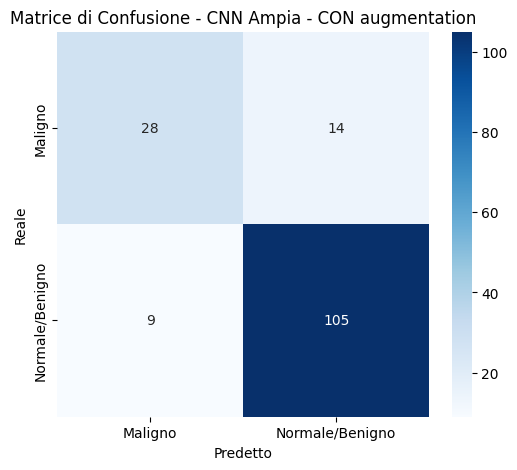

Numero totale di errori sul Test Set: 23 su 156
Maligni classificati come Normali/Benigni: 14
Normali/Benigni classificati come Maligni: 9


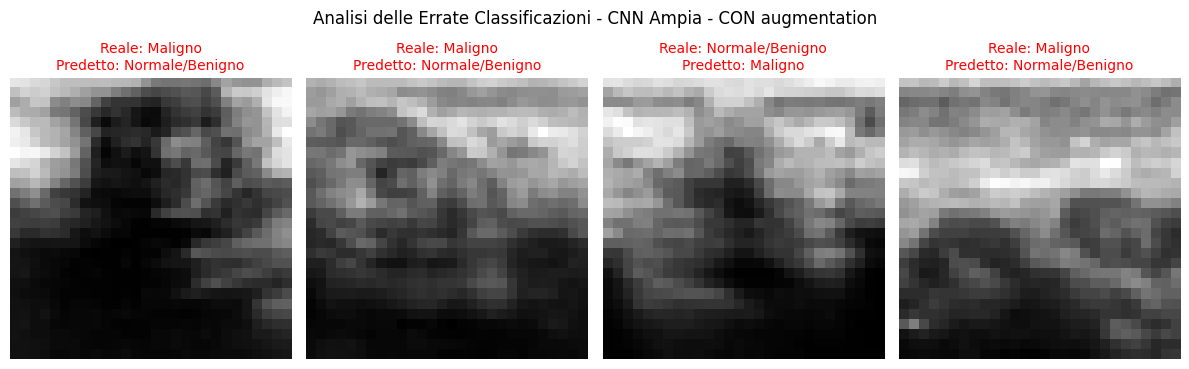

In [ ]:

# 1. MATRICE DI CONFUSIONE DEL MODELLO FINALE
# Dopo aver calcolato le metriche del modello finale,
# analizziamo più nel dettaglio le sue predizioni.
#
# La matrice di confusione permette di confrontare:
#
# - classe REALE dell'immagine;
# - classe PREDETTA dal modello.
#
# Nel nostro dataset:
#
# 0 = Maligno
# 1 = Normale/Benigno
# Calcola la matrice di confusione confrontando
# tutte le etichette reali del test set (all_targets)
# con tutte le predizioni del modello finale (all_preds).

cm = confusion_matrix(#Calcola la matrice di confusione confrontando i valori reali con quelli predetti

    all_targets,

    all_preds,

    labels=[0, 1]#la prima riga/colonna corrisponde alla classe 0 e la seconda alla 1
)


plt.figure(figsize=(6, 5))


sns.heatmap(#Disegna una mappa di calore usando la libreria seaborn

    cm,#Passa la confusion matrix

    annot=True,#Stampa i numeri assoluti dentro le caselle.

    fmt='d',

    cmap='Blues',#Imposta la scala di colore sulle tonalità di blu (più scuro = numero più alto)

    xticklabels=['Maligno','Normale/Benigno'],

    yticklabels=['Maligno','Normale/Benigno']
)

plt.xlabel('Predetto')

plt.ylabel('Reale')

plt.title(f'Matrice di Confusione - 'f'{best_model_name}')

plt.show()



# 2. ANALISI DELLE MISCLASSIFICATIONS
# La confusion matrix ci mostra quanti errori sono stati
# commessi, ma vogliamo anche identificare precisamente
# quali immagini sono state classificate in modo errato.

misclassified_idx = np.where(all_preds != all_targets)[0]#Usa NumPy per trovare gli indici posizionali di tutte le immagini in cui la predizione (all_preds) è diversa dalla realtà (all_targets)


print(
    f"Numero totale di errori sul Test Set: "
    f"{len(misclassified_idx)} "
    f"su {len(all_targets)}"
)


# Conteggio specifico dei due tipi di errore
# In un problema binario possiamo distinguere
# due tipi principali di errore:
#
# 1. Maligno classificato come Normale/Benigno
# 2. Normale/Benigno classificato come Maligno

# Cerchiamo i casi in cui contemporaneamente:
#
# classe reale     = 0  -> Maligno
# classe predetta  = 1  -> Normale/Benigno
malignant_as_benign = np.where(#Trova gli indici dei Falsi Negativi: casi in cui il tumore era Maligno (0) ma la rete ha predetto Benigno (1).

    (all_targets == 0) & (all_preds == 1)
)[0]

# Cerchiamo invece i casi in cui:
#
# classe reale     = 1  -> Normale/Benigno
# classe predetta  = 0  -> Maligno
benign_as_malignant = np.where(#Trova gli indici dei Falsi Positivi: casi in cui il tessuto era Benigno (1) ma la rete ha predetto Maligno (0).

    (all_targets == 1) & (all_preds == 0)
)[0]


print(
    "Maligni classificati come Normali/Benigni: "
    f"{len(malignant_as_benign)}"
)


print(
    "Normali/Benigni classificati come Maligni: "
    f"{len(benign_as_malignant)}"
)


# Dizionario delle etichette
label_names = {

    0: "Maligno",

    1: "Normale/Benigno"
}



# 3. VISUALIZZAZIONE DI ERRORI SIGNIFICATIVI:
#    2 FALSI NEGATIVI + 2 FALSI POSITIVI

# Consideriamo la classe maligna (label 0) come classe di interesse.
#
# Falso negativo:
# immagine realmente maligna (0), ma predetta come normale/benigna (1).
#
# Falso positivo:
# immagine realmente normale/benigna (1), ma predetta come maligna (0).


# Troviamo gli indici dei falsi negativi:
# target reale = 0 e predizione = 1.
false_negative_idx = np.where(
    (all_targets == 0) &
    (all_preds == 1)
)[0]


# Troviamo gli indici dei falsi positivi:
# target reale = 1 e predizione = 0.
false_positive_idx = np.where(
    (all_targets == 1) &
    (all_preds == 0)
)[0]


# Selezioniamo al massimo 2 falsi negativi
# e al massimo 2 falsi positivi.
selected_fn = false_negative_idx[:2]
selected_fp = false_positive_idx[:2]


# Uniamo gli indici selezionati.
selected_idx = np.concatenate([
    selected_fn,
    selected_fp
])


# Creiamo anche una lista che indica il tipo
# di errore associato a ciascuna immagine.
error_types = (
    ["Falso negativo"] * len(selected_fn)
    +
    ["Falso positivo"] * len(selected_fp)
)


# Procediamo solo se esiste almeno un errore da mostrare.
if len(selected_idx) > 0:

    num_samples = len(selected_idx)

    plt.figure(figsize=(12, 4))


    # Visualizziamo le immagini selezionate.
    for i, (idx, error_type) in enumerate(
        zip(selected_idx, error_types)
    ):

        # Recuperiamo l'immagine e la sua classe reale
        # direttamente dal test dataset.
        img, label = test_dataset[idx]


        # Rimuoviamo la dimensione del canale:
        # da [1, 28, 28] a [28, 28].
        img_display = (
            img
            .squeeze()
            .numpy()
        )


        # Annulliamo la normalizzazione:
        # Normalize(mean=0.5, std=0.5)
        # viene invertita con x * 0.5 + 0.5.
        img_display = (
            img_display * 0.5
            + 0.5
        )


        plt.subplot(
            1,
            num_samples,
            i + 1
        )


        # Mostriamo l'ecografia in scala di grigi.
        plt.imshow(
            img_display,
            cmap='gray'
        )


        # Convertiamo label reale e predizione
        # nei rispettivi nomi delle classi.
        real_str = label_names[
            int(label.item())
        ]

        pred_str = label_names[
            int(all_preds[idx])
        ]


        # Nel titolo mostriamo:
        # - tipo di errore;
        # - classe reale;
        # - classe predetta.
        plt.title(
            f"{error_type}\n"
            f"Reale: {real_str}\n"
            f"Predetto: {pred_str}",
            color='red',
            fontsize=10
        )


        plt.axis('off')


    # Titolo generale della figura.
    plt.suptitle(
        f'Analisi delle misclassifications '
        f'- {best_model_name}',
        fontsize=12
    )


    plt.tight_layout()

    plt.show()